# <center><u>**Equação do Telégrafo**</u></center>

<br>

Consideremos a propagação de sinais (tensão ou corrente elétrica) ao longo do tempo $t$ em uma linha de transmissão de comprimento $L$, levando em conta efeitos de amortecimento e dissipação. Representaremos por $u(x, t)$ o valor do sinal no ponto $x$, com $0 \leq x \leq L$, no instante de tempo $t > 0$.

<br>

Nessas condições, $u(x, t)$ satisfaz a **equação do telégrafo unidimensional**,

$$
c^2 \frac{\partial^2 u}{\partial x^2} = \frac{\partial^2 u}{\partial t^2} + 2\alpha \frac{\partial u}{\partial t} + \beta u,
$$

no domínio dado por $0 \leq x \leq L$ e $t > 0$. Nessa equação <u>hiperbólica</u>, $c > 0$ está associado à velocidade de propagação da onda, $\alpha > 0$ ao termo de amortecimento e $\beta \geq 0$ ao termo de dissipação.

<br>

Para resolvê-la analiticamente, consideramos como condições de contorno homogêneas que as extremidades da linha são mantidas nulas:

$$u(0, t) = 0, \quad \quad u(L, t) = 0, \quad \quad \forall t > 0.$$

Como há uma derivada segunda em $t$, consideramos também que conhecemos o perfil inicial do sinal,

$$u(x, 0) = f(x), \quad \quad \forall x \in [0, L],$$

e que sua taxa de variação inicial (velocidade inicial) é nula,

$$u_t(x, 0) = 0, \quad \quad \forall x \in [0, L].$$

<br><br>

***

<br>

# **Resolução analítica computacional**

Vamos começar definindo as variáveis, constantes simbólicas e a equação do telégrafo computacionalmente com a biblioteca `SymPy`.

In [2]:
%pip install sympy numpy matplotlib scipy

  Using cached numpy-2.5.5-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/6.3 MB ? eta -:--:--
   ---------------------------------------- 6.3/6.3 MB 39.2 MB/s  0:00:00
   ---------------------------------------- 0.0/536.2 kB ? eta -:--:--
   ---------------------------------------- 536.2/536.2 kB 37.0 MB/s  0:00:00
Using cached numpy-2.5.5-cp314-cp314-win_amd64.whl (12.7 MB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------------------------- 9.5/9.5 MB 66.0 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   --------------- ------------------------ 14.7/37.4 MB 71.3 MB/s eta 0:00:01
   ----------------------------- ---------- 27.8/37.4 MB 68.2 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 61.1 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ?

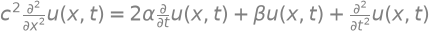

In [3]:
import sympy as sp
sp.init_printing()

# definindo variáveis, constantes e função simbólica
x, t = sp.symbols('x, t', real=True)
c, alpha, beta = sp.symbols('c, alpha, beta', positive=True)

u = sp.Function('u')(x, t)

# definindo a equação do telégrafo
eq_telegrafo = sp.Eq(
    c**2 * sp.Derivative(u, x, 2),
    sp.Derivative(u, t, 2) + 2*alpha*sp.Derivative(u, t) + beta*u
)

eq_telegrafo

<br>

## **Separação de variáveis**

Assumindo que a solução da equação diferencial é da forma

$$u(x, t) = X(x)T(t),$$

a equação é reescrita como

\begin{align}
c^2 \frac{\partial^2 (XT)}{\partial x^2} &= \frac{\partial^2 (XT)}{\partial t^2} + 2\alpha \frac{\partial (XT)}{\partial t} + \beta (XT) \\\\
\implies c^2 X''T &= XT'' + 2\alpha XT' + \beta XT \\\\
\implies \frac{X''}{X} &= \frac{1}{c^2} \frac{T'' + 2\alpha T' + \beta T}{T}.
\end{align}

Abaixo, separamos as variáveis simbolicamente com `sp.pde_separate` (note que o SymPy pode agrupar a constante $\beta/c^2$ no lado de $X$, o que é equivalente a deslocar a constante de separação).

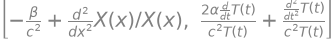

In [4]:
X = sp.Function('X')(x)
T = sp.Function('T')(t)

# separando as variáveis
sp.pde_separate(eq_telegrafo, u, [X, T], strategy='mul')

<br>

O lado esquerdo da equação não depende de $t$ e o lado direito não depende de $x$, portanto ambos devem ser iguais a alguma constante $-\lambda$ (o sinal negativo é escolhido por conveniência). Assim, obtemos as duas equações diferenciais ordinárias:

$$\frac{X''}{X} = -\lambda, \quad \quad \frac{T'' + 2\alpha T' + \beta T}{c^2 T} = -\lambda.$$

<br>

Descartando as soluções identicamente nulas ($X \equiv 0$ ou $T \equiv 0$), as condições de contorno homogêneas e a condição de derivada inicial nula ficam:

$$u(0, t) = 0,\ \ \forall t>0 \quad\implies\quad X(0)T(t)=0,\ \ \forall t>0 \quad\implies\quad X(0)=0$$
$$u(L, t) = 0,\ \ \forall t>0 \quad\implies\quad X(L)T(t)=0,\ \ \forall t>0 \quad\implies\quad X(L)=0,$$

e, analogamente,

$$u_t(x, 0) = 0,\ \ \forall x\in[0, L] \quad\implies\quad X(x)T'(0)=0,\ \ \forall x\in[0, L] \quad\implies\quad T'(0)=0.$$

<br>

Começamos definindo o problema de valor inicial na variável espacial $x$:

$$
X'' = -\lambda X, \quad X(0) = 0.
$$

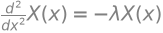

In [5]:
Lambda = sp.symbols('lambda', positive=True, real=True)

# definindo a EDO em X
edo_X = sp.Eq(sp.Derivative(X, x, 2), -Lambda * X)
edo_X

Agora resolvemos a EDO em $X$ impondo a condição de contorno $X(0) = 0$.

In [6]:
# resolvendo a EDO com a condição de contorno X(0) = 0
sp.dsolve(edo_X, X, ics={X.subs(x, 0): 0})

Assim, vemos que a solução fundamental em $x$ é

$$
X(x) = \sin(\sqrt{\lambda}x).
$$

Podemos agora considerar a outra condição de contorno homogênea,

\begin{align}
&X(L) = 0 \\
\implies &\sin\big(\sqrt{\lambda} L\big) = 0,
\end{align}

para determinar os possíveis valores de $\lambda$.

In [7]:
L = sp.symbols('L', positive=True)

# definindo a equação para lambda
eq_lambda = sp.Eq(sp.sin(sp.sqrt(Lambda) * L), 0)
eq_lambda

Resolvendo computacionalmente para $\lambda$:

In [8]:
# resolvendo em lambda
sp.solve(eq_lambda, Lambda)

Note que, quando resolvemos computacionalmente essa equação, o `SymPy` retorna apenas uma solução, $\big(\frac{\pi}{L}\big)^2$, referente a $n = 1$. Mas a função seno se anula em todos os múltiplos inteiros de $\pi$, logo os possíveis valores de $\lambda$ são

$$\lambda = \Big(\frac{n\pi}{L}\Big)^2, \quad n = 1, 2, 3, \dots$$

<br>

Assim, as respectivas soluções fundamentais espaciais são da forma

\begin{align}
X_n(x) &= \sin(\sqrt{\lambda}x) \\
&= \sin\Big(\frac{n\pi x}{L}\Big), \quad n = 1, 2, 3, \dots .
\end{align}

<br>

***

<br>

Substituindo $\lambda = \big(\frac{n\pi}{L}\big)^2$ na outra EDO, obtemos

$$
T_n'' + 2\alpha T_n' + \left(\beta + c^2\Big(\frac{n\pi}{L}\Big)^2\right)T_n = 0,
$$

para cada $n = 1, 2, 3, \dots$, cuja solução deve satisfazer a condição inicial

$$T_n'(0) = 0.$$

Definindo essa EDO computacionalmente:

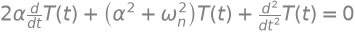

In [18]:
n = sp.symbols('n', integer=True, positive=True)
omega_n = sp.symbols('omega_n', positive=True)

# definindo a EDO em T com beta + c^2*(n*pi/L)^2 = omega_n^2 + alpha^2
edo_T = sp.Eq(
    sp.Derivative(T, t, 2) + 2*alpha*sp.Derivative(T, t) + (omega_n**2 + alpha**2)*T,
    0
)
edo_T

Obtendo a solução geral da EDO em $T$ com a condição inicial $T'(0) = 0$:

In [19]:
# obtendo a solução geral da EDO com a condição inicial T'(0) = 0
sp.simplify(sp.dsolve(edo_T, T, ics={sp.Derivative(T, t).subs(t, 0): 0}))

<br>

No regime oscilatório amortecido — quando $\omega_n = \sqrt{c^2\big(\frac{n\pi}{L}\big)^2 + \beta - \alpha^2} > 0$, o que sempre ocorre para $n$ suficientemente grande — podemos usar a **fórmula de Euler** ($e^{i\theta} = \cos\theta + i\sin\theta$) para reescrever as exponenciais complexas em termos de senos e cossenos, obtendo a solução fundamental temporal:

$$T_n(t) = e^{-\alpha t}\left[\cos(\omega_n t) + \frac{\alpha}{\omega_n}\sin(\omega_n t)\right].$$

<br>

Assim, as soluções fundamentais da equação do telégrafo com as condições de fronteira $u(0, t) = u(L, t) = 0$ para $t > 0$ e $u_t(x, 0) = 0$ para $x \in [0, L]$ são:

\begin{align}
u_n(x, t) &= X_n(x)T_n(t) \\\\
&= e^{-\alpha t}\left[\cos(\omega_n t) + \frac{\alpha}{\omega_n}\sin(\omega_n t)\right]\sin\Big(\frac{n\pi x}{L}\Big),
\end{align}

para $n = 1, 2, 3, \dots$.

<br>

Como a equação é linear e as condições consideradas até agora são todas homogêneas, pelo **princípio da superposição**, a <u>solução geral</u> é dada pelas combinações lineares das soluções fundamentais:

$$
u(x, t) = \sum_{n=1}^{\infty} c_n \, e^{-\alpha t}\left[\cos(\omega_n t) + \frac{\alpha}{\omega_n}\sin(\omega_n t)\right]\sin\Big(\frac{n\pi x}{L}\Big),
$$

onde $c_n \in \mathbb{R}$.

<br>

Podemos determinar esses escalares utilizando a condição inicial restante,

$$u(x, 0) = f(x),$$

donde obtemos

\begin{align}
u(x, 0) &= \sum_{n=1}^{\infty} c_n \, e^{0}\left[\cos(0) + \frac{\alpha}{\omega_n}\sin(0)\right]\sin\Big(\frac{n\pi x}{L}\Big) \\\\
\implies f(x) &= \sum_{n=1}^{\infty} c_n \sin\Big(\frac{n\pi x}{L}\Big).
\end{align}

Ou seja, os coeficientes $c_n$ são exatamente os **coeficientes da série de Fourier de senos da função $f$** em $[0, L]$, que são dados por

$$
c_n = \frac{2}{L}\int_{0}^{L} f(x)\sin\Big(\frac{n\pi x}{L}\Big)dx.
$$